In [1]:
import mlflow
import mlflow.sklearn
import pandas as pd

from finsent.config import MLFLOW_TRACKING_URI, PROJECT_ROOT
from finsent.data.split import load_splits
from finsent.models.evaluate import evaluate, plot_confusion_matrix

d:\finsent\fs\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ART = PROJECT_ROOT / "artifacts"
TFIDF_RUN_ID = "680e57c0dae34002bafcb1c5f5ba3aab"   # tfidf_lr_balanced

# 1. FinBERT predictions (saved on Colab)
ft = pd.read_csv(ART / "finbert_ft" / "val_preds.csv")
zs = pd.read_csv(ART / "finbert_zeroshot_val.csv")

In [4]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
tfidf = mlflow.sklearn.load_model(f"runs:/{TFIDF_RUN_ID}/model")
_, val, _ = load_splits()
tfidf_preds = tfidf.predict(val["text"])

# 3. Same tweets, same order?
assert (ft["text"].values == val["text"].values).all(), "fine-tuned CSV misaligned"
assert (zs["text"].values == val["text"].values).all(), "zero-shot CSV misaligned"


In [5]:
df = pd.DataFrame(
    {
        "text": val["text"].values,
        "label": val["label"].values,
        "pred_ft": ft["pred"].values,
        "conf_ft": ft["confidence"].values,
        "pred_tfidf": tfidf_preds,
        "pred_zs": zs["pred"].values,
    }
)
df["correct_ft"] = df["pred_ft"] == df["label"]
df["correct_tfidf"] = df["pred_tfidf"] == df["label"]
df["correct_zs"] = df["pred_zs"] == df["label"]

print(df.shape, "| missing values:", df.isna().sum().sum())
print(df[["correct_ft", "correct_tfidf", "correct_zs"]].mean().round(3))
df.head()

(1410, 9) | missing values: 0
correct_ft       0.878
correct_tfidf    0.800
correct_zs       0.716
dtype: float64


,text,label,pred_ft,conf_ft,pred_tfidf,pred_zs,correct_ft,correct_tfidf,correct_zs
0,$FTS: Fortis announced the appointment of Davi...,neutral,neutral,0.995937,neutral,neutral,True,True,True
1,UPDATE 2-Major FirstGroup shareholders call fo...,neutral,neutral,0.991375,neutral,neutral,True,True,True
2,Here’s Everything To Know About Airbnb’s 2020 ...,neutral,neutral,0.996911,neutral,neutral,True,True,True
3,Highlight: “Theres certainly a lot of U.S bank...,neutral,neutral,0.986797,neutral,neutral,True,True,True
4,Barclays Executive’s Lawyer Likens Prosecutor ...,neutral,neutral,0.995873,neutral,neutral,True,True,True


FinBERT fine-tuned:
pred_ft   negative  neutral  positive   All
label                                      
negative       176       34         3   213
neutral         42      823        46   911
positive         7       40       239   286
All            225      897       288  1410

TF-IDF balanced (for comparison):
pred_tfidf  negative  neutral  positive   All
label                                        
negative         138       51        24   213
neutral           51      782        78   911
positive          28       50       208   286
All              217      883       310  1410


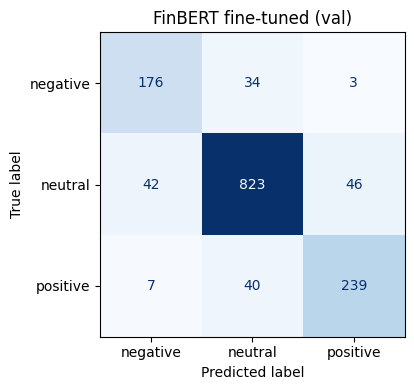

In [6]:
fig = plot_confusion_matrix(df["label"], df["pred_ft"], "FinBERT fine-tuned (val)")

print("FinBERT fine-tuned:")
print(pd.crosstab(df["label"], df["pred_ft"], margins=True))
print("\nTF-IDF balanced (for comparison):")
print(pd.crosstab(df["label"], df["pred_tfidf"], margins=True))

In [7]:
recall = pd.DataFrame(
    {
        "finbert_ft": df.groupby("label")["correct_ft"].mean(),
        "tfidf": df.groupby("label")["correct_tfidf"].mean(),
    }
).round(3)
recall

,finbert_ft,tfidf
label,,
negative,0.826,0.648
neutral,0.903,0.858
positive,0.836,0.727


In [8]:
pd.set_option("display.max_colwidth", None)

errors = df[~df["correct_ft"]]
print("Total FinBERT errors:", len(errors))

errors.sort_values("conf_ft", ascending=False).head(15)[
    ["text", "label", "pred_ft", "conf_ft", "pred_tfidf"]
]

Total FinBERT errors: 172


,text,label,pred_ft,conf_ft,pred_tfidf
263,$CNK - Cinemark Holdings (CNK) Presents At Southwest Ideas Investor Conference - Slideshow. Get more updates here:…,positive,neutral,0.996879,neutral
214,FCC Bigfoots Satellite Companies,negative,neutral,0.996673,neutral
1192,Morgan Stanley joins mortgage sector bulls,positive,neutral,0.995672,negative
29,Thiel driving FB division on political ads - WSJ,negative,neutral,0.995579,neutral
556,Baird returns to Wingstop bull camp,positive,neutral,0.995486,positive
102,"KUDLOW: NO PLANS FOR CHINA, U.S. LEADERS TO MEET AT PRESENT Tariff deadline is in 9 days",negative,neutral,0.995404,neutral
1020,OPEC's New Year's Gift To Oil Bulls. Follow this and any other stock on Seeking Alpha! #business #finance #markets,positive,neutral,0.995119,neutral
850,"Newspaper fights Warner Bros, 'Richard Jewell' over depiction of reporter trading sex for a scoop",negative,neutral,0.993641,neutral
247,Saint-Gobain North America Announces Largest Renewable Energy Deal in Company’s 354-Year History,positive,neutral,0.993595,neutral
913,$NFLX - New Netflix bear steps out,negative,neutral,0.993298,negative


In [11]:
pd.crosstab(df["correct_ft"], df["correct_tfidf"])


correct_tfidf,False,True
correct_ft,,
False,106,66
True,176,1062


In [12]:
pd.crosstab(df["label"], df["pred_zs"])

pred_zs,negative,neutral,positive
label,,,
negative,155,42,16
neutral,118,676,117
positive,28,80,178
